# Project 2: Evolutionary Algorithms
Machine Learning T-504-ITML 

Group: Dagur Smári (dagurss24@ru.is) and Kamil Michal (kamil24@ru.is)

## The Setup

In [1]:
import random
import numpy as np
seed = 42240 #last 5 digit of smallest student number
random.seed(seed)
np.random.seed(seed)
import matplotlib.pyplot as plt
import pandas as pd

---
## Task 1: 6-bit Representation of Integers

In [2]:
## Functions to go from phenome type to genotype and back
def geno_to_pheno(individuals):
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

### 1.1 Initialization function

In [3]:
def initialization_population(pop_size):
    
    population = []
    for i in range(pop_size):
        digit = random.randint(0, 63)
        population.append(digit)
    return pheno_to_geno(population)

**Subtask: generate 4 individuals**

In [4]:
test_population = initialization_population(4)
print("Individuals:", test_population)
print("As integers:", geno_to_pheno(test_population))
print("Output type: a", type(test_population).__name__, "of", type(test_population[0]).__name__ + "s",
      "(each of length", len(test_population[0]), ")")

Individuals: [[0, 0, 0, 1, 0, 0], [1, 1, 1, 0, 0, 0], [0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 0, 1]]
As integers: [4, 56, 28, 33]
Output type: a list of lists (each of length 6 )


### 1.2 Fitness function

In [5]:
def fitness(individuals):

    # Takes in geno values [x, x, x, x, x, x]
    x_values = geno_to_pheno(individuals)
    result = []
    
    for x in x_values:
        
        if x >= 32:
            y = x - 64
        else:
            y = x
            
        fitness_value = (
            -0.00008333 * pow(y, 6)
            - 0.001 * pow(y, 5)
            + 0.09375 * pow(y, 4)
            + 1.16667 * pow(y, 3)
            - 19.53125 * pow(y, 2)
            - 234.375 * y
            + 8350
        )

        result.append(fitness_value)    

    #return pheno values
    return result

**Subtask: Check for individual = [[0, 1, 0, 1, 0, 1]]**

In [6]:
individual = [[0, 1, 0, 1, 0, 1]]
print("Expected fitness value: 12620.97")
print("Fitness value: " + str(round(fitness(individual)[0], 2)))

Expected fitness value: 12620.97
Fitness value: 12620.98


**Subtask: Fitness landscape and min/max x-values**

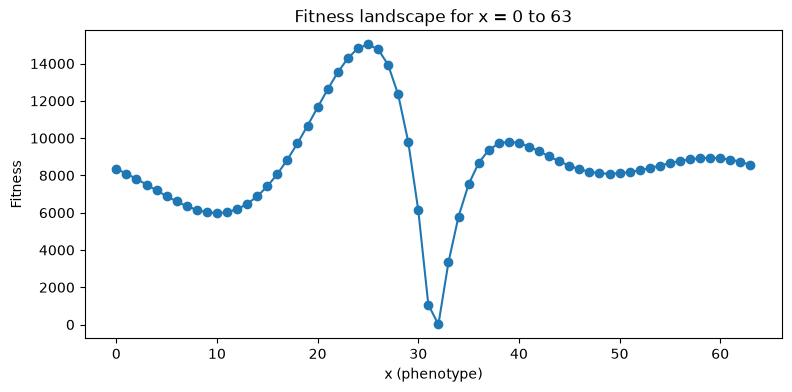

Max fitness: 15024.04 at x = 25 or [0, 1, 1, 0, 0, 1]
Min fitness: 4.08 at x = 32 or [1, 0, 0, 0, 0, 0]


In [7]:
# Plot of the landscape
x_values = list(range(64))
fitness_values = fitness(pheno_to_geno(x_values))

plt.figure(figsize=(9, 4))
plt.plot(x_values, fitness_values, marker="o")
plt.xlabel("x (phenotype)")
plt.ylabel("Fitness")
plt.title("Fitness landscape for x = 0 to 63")
plt.show()

# Which x gives min and max fitness
x_max = x_values[fitness_values.index(max(fitness_values))]
x_min = x_values[fitness_values.index(min(fitness_values))]

print("Max fitness:", round(max(fitness_values), 2), "at x =", x_max, "or", pheno_to_geno([x_max])[0])
print("Min fitness:", round(min(fitness_values), 2), "at x =", x_min, "or", pheno_to_geno([x_min])[0])

### 1.3 Parent selection function

In [8]:
def parent_selection(individuals, fitness_values):

    total_fitness = sum(fitness_values)
    fitness_val_probabilities = []

    for i in range(len(fitness_values)):
        fitness_val_probabilities.append(fitness_values[i] / total_fitness)

    selected = np.random.choice(len(individuals),size=len(individuals),replace=True,p=fitness_val_probabilities)

    parents = []
    for i in selected:
        parents.append(list(individuals[i]))
    return parents

## Windowing needed for bonus

**Subtask: Testing on four individuals**

In [9]:
# Use x_values, fitness_values, x_min and x_max from fitness cell

# the 2 x values with fitness closest to the middle of the fitness range
middle = (min(fitness_values) + max(fitness_values)) / 2
closest = sorted(x_values, key=lambda x: abs(fitness_values[x] - middle))[:2]

test_x = [x_min, x_max] + closest
test_individuals = pheno_to_geno(test_x)
test_fitness = fitness(test_individuals)

for x, g, f in zip(test_x, test_individuals, test_fitness):
    print(f"x = {x} (genotype = {g}) fitness = {round(f, 2)} probability = {round((f / sum(test_fitness)), 4)}")

parents = parent_selection(test_individuals, test_fitness)
print("------------------------")
print("Parents: ", parents)
print("As x: ", geno_to_pheno(parents))

x = 32 (genotype = [1, 0, 0, 0, 0, 0]) fitness = 4.08 probability = 0.0001
x = 25 (genotype = [0, 1, 1, 0, 0, 1]) fitness = 15024.04 probability = 0.4998
x = 3 (genotype = [0, 0, 0, 0, 1, 1]) fitness = 7509.88 probability = 0.2499
x = 35 (genotype = [1, 0, 0, 0, 1, 1]) fitness = 7519.29 probability = 0.2502
------------------------
Parents:  [[0, 0, 0, 0, 1, 1], [0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1]]
As x:  [3, 25, 25, 25]


### 1.4 Crossover

In [10]:
def one_point_crossover(parents, crossover_prob):
     
    off_spring = []

    for i in range(0, len(parents), 2):

        if i == len(parents) - 1:
            off_spring.append(parents[i].copy())
            break

        number = random.random()   
        if number > crossover_prob:
            off_spring.append(parents[i].copy())
            off_spring.append(parents[i+1].copy())
            continue

        crossover_point = random.randint(1, len(parents[i]) - 1)

        offspring1 = parents[i]
        offspring2 = parents[i+1]

        new_offspring1 = offspring1[:crossover_point] + offspring2[crossover_point:]
        new_offspring2 = offspring2[:crossover_point] + offspring1[crossover_point:]

        off_spring.append(new_offspring1)
        off_spring.append(new_offspring2)

    return off_spring

**Subtask: Crossover of two parents**

In [11]:
test_parents = [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]
children = one_point_crossover(test_parents, 1.0)

print("Parents:  ", test_parents)
print("Offspring:", children)
cut = children[0].index(1)
print("Cut point: after gene", cut)
print("With pc = 0:", one_point_crossover(test_parents, 0.0))

Parents:   [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]
Offspring: [[0, 1, 1, 1, 1, 1], [1, 0, 0, 0, 0, 0]]
Cut point: after gene 1
With pc = 0: [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]


### 1.5 Mutation

In [12]:
def mutation(individuals, mutation_prob):
    
    mutated = []

    for i in individuals:
        new_individual = i.copy()

        for j in range(len(new_individual)):
            number = random.random()
            if number <= mutation_prob:
                # flip the gene
                new_individual[j] = 1 - new_individual[j]

        mutated.append(new_individual)

    return mutated

**Subtask: mutation of one individual**

In [13]:
individual = [[0, 1, 0, 1, 0, 1]]
mutated_02 = mutation(individual, 0.2)[0]
mutated_09 = mutation(individual, 0.9)[0]

# count how many genes were flipped
flips_02 = 0
flips_09 = 0
for j in range(len(individual[0])):
    if individual[0][j] != mutated_02[j]:
        flips_02 += 1
    if individual[0][j] != mutated_09[j]:
        flips_09 += 1

print("Original individual:", individual[0])
print("-----------")
print("After mutation with pm = 0.2:", mutated_02, "->", flips_02, "genes flipped (expected 6 x 0.2 = 1.2)")
print("After mutation with pm = 0.9:", mutated_09, "->", flips_09, "genes flipped (expected 6 x 0.9 = 5.4)")

Original individual: [0, 1, 0, 1, 0, 1]
-----------
After mutation with pm = 0.2: [1, 1, 0, 0, 0, 0] -> 3 genes flipped (expected 6 x 0.2 = 1.2)
After mutation with pm = 0.9: [1, 0, 1, 0, 1, 1] -> 5 genes flipped (expected 6 x 0.9 = 5.4)


Comment on whether the number of bit flips is expected

(maybe do more/better tests)

### 1.6 Survivor selection

In [14]:
def survivor_selection(individuals, offspring, fitness_individuals, fitness_offspring):
    survivors = []

    all_individuals = individuals + offspring
    all_fitness = list(fitness_individuals) + list(fitness_offspring)

    # sort positions from highest to lowest
    for k in range(len(individuals)):
        # find the fittest one left, move it to the survivors
        best = all_fitness.index(max(all_fitness))
        survivors.append(all_individuals.pop(best))
        all_fitness.pop(best)

    return survivors

**Subtask: Test fitter individual**

In [15]:
parent = [[0, 1, 0, 1, 0, 1]]   # x = 21
child = [[0, 1, 1, 0, 0, 1]]     # x = 25
survivor = survivor_selection(parent, child, fitness(parent), fitness(child))

print("Parent:", parent[0], "Fitness =", round(fitness(parent)[0], 2))
print("Offspring:", child[0], "Fitness =", round(fitness(child)[0], 2))
print("------------")
print("Survivor:", survivor[0], "Fitness =", round(fitness(survivor)[0], 2))

Parent: [0, 1, 0, 1, 0, 1] Fitness = 12620.98
Offspring: [0, 1, 1, 0, 0, 1] Fitness = 15024.04
------------
Survivor: [0, 1, 1, 0, 0, 1] Fitness = 15024.04


In [16]:
# Case 2: the population individual is fitter
parent = [[0, 1, 1, 0, 0, 1]]    # x = 25
child = [[1, 0, 0, 0, 0, 0]]     # x = 32
survivor = survivor_selection(parent, child, fitness(parent), fitness(child))

print("Parent:", parent[0], "Fitness =", round(fitness(parent)[0], 2))
print("Offspring:", child[0], "Fitness =", round(fitness(child)[0], 2))
print("------------")
print("Survivor:", survivor[0], "Fitness =", round(fitness(survivor)[0], 2))
print()

# Population size stays the same: the 4 test individuals from 1.3 and the 4 parents from 1.3 as offspring
new_population = survivor_selection(test_individuals, parents, fitness(test_individuals), fitness(parents))
print("Population:", geno_to_pheno(test_individuals), "size", len(test_individuals))
print("Offspring: ", geno_to_pheno(parents), "size", len(parents))
print("Survivors: ", geno_to_pheno(new_population), "size", len(new_population))

Parent: [0, 1, 1, 0, 0, 1] Fitness = 15024.04
Offspring: [1, 0, 0, 0, 0, 0] Fitness = 4.08
------------
Survivor: [0, 1, 1, 0, 0, 1] Fitness = 15024.04

Population: [32, 25, 3, 35] size 4
Offspring:  [3, 25, 25, 25] size 4
Survivors:  [25, 25, 25, 25] size 4


### 1.7 Complete version of SGA (Loop)

In [17]:
def sga(pop_size, n_iterations, crossover_prob, mutation_prob,
        init_function=initialization_population, fitness_function=fitness,
        crossover_function=one_point_crossover, mutation_function=mutation,
        print_every=1, k = None):

    # start with random population and its fitness
    
    if k is None:
        population = init_function(pop_size)
    else:
        population = init_function(pop_size, k)
        
    population_fitness = fitness_function(population)

    # save the history (to show improvement)
    best_history = [max(population_fitness)]
    average_history = [sum(population_fitness) / pop_size]

    if print_every > 0:
        print(f"Iteration 0: average fitness = {round(average_history[-1], 2)}, best fitness = {round(best_history[-1], 2)}")

    for iteration in range(1, n_iterations + 1):

        # repeated steps in every iteration
        parents = parent_selection(population, population_fitness)

        if k is None:
            offspring = crossover_function(parents, crossover_prob)
        else:
            offspring = crossover_function(parents, crossover_prob, k)
        
        offspring = mutation_function(offspring, mutation_prob)
        offspring_fitness = fitness_function(offspring)

        population = survivor_selection(population, offspring, population_fitness, offspring_fitness)
        population_fitness = fitness_function(population)

        # save and show the average and best fitness of this iteration
        best_history.append(max(population_fitness))
        average_history.append(sum(population_fitness) / pop_size)

        # print every # number of lines (for later tasks, can change to every 100 lines for example)
        if print_every > 0 and iteration % print_every == 0:
            print(f"Iteration {iteration}: average fitness = {round(average_history[-1], 2)}, best fitness = {round(best_history[-1], 2)}")

    return population, population_fitness, best_history, average_history

**Subtask: Display best & average fitness**

Iteration 0: average fitness = 7768.79, best fitness = 9549.33
Iteration 1: average fitness = 9361.16, best fitness = 11650.24
Iteration 2: average fitness = 9722.36, best fitness = 11650.24
Iteration 3: average fitness = 9759.42, best fitness = 11650.24
Iteration 4: average fitness = 10104.51, best fitness = 12620.98
Iteration 5: average fitness = 10959.15, best fitness = 15024.04
Iteration 6: average fitness = 12789.95, best fitness = 15024.04
Iteration 7: average fitness = 13321.47, best fitness = 15024.04
Iteration 8: average fitness = 13693.39, best fitness = 15024.04
Iteration 9: average fitness = 14545.92, best fitness = 15024.04
Iteration 10: average fitness = 15024.04, best fitness = 15024.04
Iteration 11: average fitness = 15024.04, best fitness = 15024.04
Iteration 12: average fitness = 15024.04, best fitness = 15024.04
Iteration 13: average fitness = 15024.04, best fitness = 15024.04
Iteration 14: average fitness = 15024.04, best fitness = 15024.04
Iteration 15: average fit

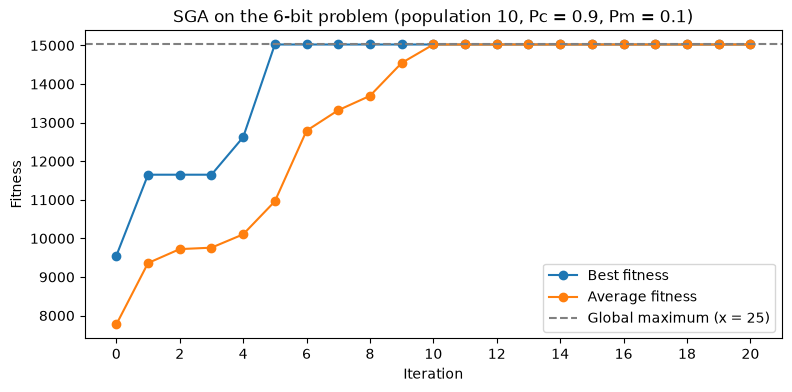

In [18]:
population, population_fitness, best_history, average_history = sga(10, 20, 0.9, 0.1)

print("------------------------")
print("Final population (x):", geno_to_pheno(population))

#Simple plot
plt.figure(figsize=(9, 4))
plt.plot(best_history, marker="o", label="Best fitness")
plt.plot(average_history, marker="o", label="Average fitness")
plt.axhline(max(fitness_values), color="grey", linestyle="--", label="Global maximum (x = 25)")
plt.xticks(range(0, len(best_history), 2))
plt.xlabel("Iteration")
plt.ylabel("Fitness")
plt.title("SGA on the 6-bit problem (population 10, Pc = 0.9, Pm = 0.1)")
plt.legend()
plt.show()

In [19]:
# check if the best and average fitness ever went down
best_never_decreases = True
average_never_decreases = True
for i in range(1, len(best_history)):
    if best_history[i] < best_history[i - 1]:
        best_never_decreases = False
    if average_history[i] < average_history[i - 1] - 1e-9:   # tiny tolerance for rounding
        average_never_decreases = False

print("Best fitness never decreases:   ", best_never_decreases)
print("Average fitness never decreases:", average_never_decreases)

Best fitness never decreases:    True
Average fitness never decreases: True


### 1.8 Testing SGA

In [20]:
pop_sizes = [4, 6, 10, 20, 50]
iteration_counts = [1, 5, 10, 20, 50]
n_runs = 30   # each combination is run 30 times, one run alone is too random

rows = []

for pop_size in pop_sizes:
    for n_iterations in iteration_counts:

        best_total = 0
        average_total = 0
        found_max = 0

        for run in range(n_runs):
            population, population_fitness, best_history, average_history = sga(pop_size, n_iterations, 0.9, 0.1, print_every=0)

            best_total += max(population_fitness)
            average_total += sum(population_fitness) / pop_size
            if 25 in geno_to_pheno(population):
                found_max += 1

        rows.append([pop_size, n_iterations, best_total / n_runs, average_total / n_runs, 100 * found_max / n_runs])

results = pd.DataFrame(rows, columns=["Population size", "Iterations", "Mean best", "Mean average", "% found x = 25"])

print("Mean best fitness (rows: population size, columns: iterations)")
print(results.pivot(index="Population size", columns="Iterations", values="Mean best").round(1))
print()
print("Mean average fitness")
print(results.pivot(index="Population size", columns="Iterations", values="Mean average").round(1))
print()
print("% of runs that found the global maximum x = 25")
print(results.pivot(index="Population size", columns="Iterations", values="% found x = 25").round(0))

Mean best fitness (rows: population size, columns: iterations)
Iterations            1        5        10       20       50
Population size                                             
4                11221.4  13913.1  12945.9  14107.0  14301.0
6                13013.3  14375.9  14836.6  14515.4  14900.9
10               14200.4  14552.8  14984.4  14974.8  14925.5
20               14611.5  14983.2  15017.2  15024.0  15024.0
50               14968.1  15024.0  15024.0  15024.0  15024.0

Mean average fitness
Iterations            1        5        10       20       50
Population size                                             
4                10131.4  13173.2  12871.7  13987.9  14301.0
6                10462.7  14098.8  14665.5  14514.9  14894.3
10               10800.8  14177.1  14872.5  14971.4  14925.5
20               10731.7  14679.3  14981.5  15021.3  15024.0
50               10784.7  14693.0  15022.4  15024.0  15024.0

% of runs that found the global maximum x = 25
Iterations   

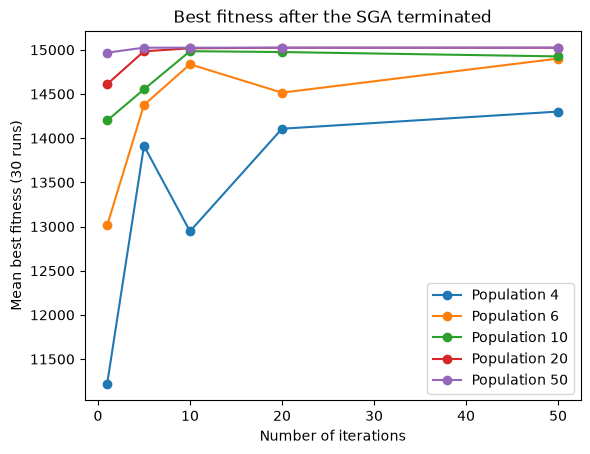

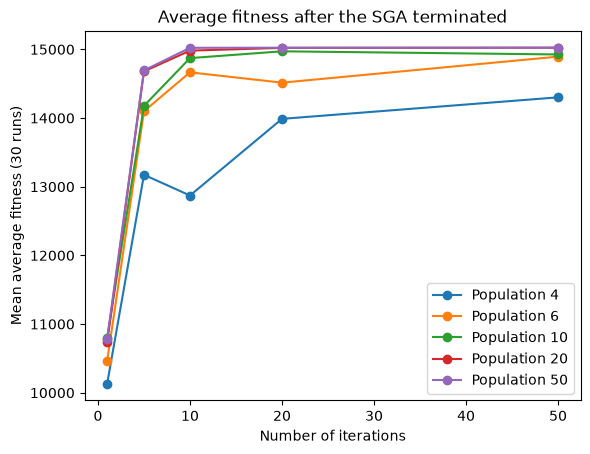

In [21]:
# Plots
for pop_size in pop_sizes:
    rows_for_size = results[results["Population size"] == pop_size]
    plt.plot(rows_for_size["Iterations"], rows_for_size["Mean best"], marker="o", label=f"Population {pop_size}")
plt.xlabel("Number of iterations")
plt.ylabel("Mean best fitness (30 runs)")
plt.title("Best fitness after the SGA terminated")
plt.legend()
plt.show()

for pop_size in pop_sizes:
    rows_for_size = results[results["Population size"] == pop_size]
    plt.plot(rows_for_size["Iterations"], rows_for_size["Mean average"], marker="o", label=f"Population {pop_size}")
plt.xlabel("Number of iterations")
plt.ylabel("Mean average fitness (30 runs)")
plt.title("Average fitness after the SGA terminated")
plt.legend()
plt.show()

### Extra checks for Task 1
These use random numbers, so they are placed last and do not change any of the results above.

In [22]:
# 1.5: repeat the mutation many times to see the average number of flips
for pm in [0.2, 0.9]:
    total_flips = 0
    for r in range(10000):
        mutated = mutation(individual, pm)
        for j in range(len(individual[0])):
            if individual[0][j] != mutated[0][j]:
                total_flips += 1
    print(f"pm = {pm}: average flips over 10000 mutations = {round(total_flips / 10000, 3)} (expected {round(6 * pm, 1)})")

pm = 0.2: average flips over 10000 mutations = 1.206 (expected 1.2)
pm = 0.9: average flips over 10000 mutations = 5.399 (expected 5.4)


In [23]:
# 1.8: where do the runs that miss x = 25 end up? (population 4 and 6, 50 iterations)
for pop_size in [4, 6]:
    end_points = []
    for run in range(n_runs):
        population, population_fitness, best_history, average_history = sga(pop_size, 50, 0.9, 0.1, print_every=0)
        best_x = geno_to_pheno(population)[population_fitness.index(max(population_fitness))]
        end_points.append(best_x)
    counts = {x: end_points.count(x) for x in sorted(set(end_points))}
    print(f"Population {pop_size}: best x at the end of the 30 runs -> {counts}")

Population 4: best x at the end of the 30 runs -> {23: 8, 24: 1, 25: 21}
Population 6: best x at the end of the 30 runs -> {23: 3, 25: 26, 26: 1}


In [24]:
# 1.8: x = 23 is a trap: every single bit flip gives a lower fitness
trap = pheno_to_geno([23])[0]
print("x = 23:", trap, "fitness =", round(fitness([trap])[0], 2))
for i in range(6):
    neighbour = trap.copy()
    neighbour[i] = 1 - neighbour[i]
    print(neighbour, "x =", geno_to_pheno([neighbour])[0], "fitness =", round(fitness([neighbour])[0], 2))

x = 23: [0, 1, 0, 1, 1, 1] fitness = 14285.14
[1, 1, 0, 1, 1, 1] x = 55 fitness = 8656.7
[0, 0, 0, 1, 1, 1] x = 7 fitness = 6350.99
[0, 1, 1, 1, 1, 1] x = 31 fitness = 1066.37
[0, 1, 0, 0, 1, 1] x = 19 fitness = 10669.44
[0, 1, 0, 1, 0, 1] x = 21 fitness = 12620.98
[0, 1, 0, 1, 1, 0] x = 22 fitness = 13523.25


---
## Task 2: Knapsack for ”data 1001” data set

### 2.1 Load the data set

In [25]:
data = pd.read_csv("data_1001.csv")

item_values = data["Value"].tolist()
item_weights = data["Weight"].tolist()

print("Size of the data set:", data.shape[0], "items and", data.shape[1], "columns")
print(data.describe().round(1))

Size of the data set: 1001 items and 2 columns
         Value    Weight
count   1001.0    1001.0
mean    5762.2   10134.0
std     5770.4    6386.1
min    -4299.0       1.0
25%      940.0    5245.0
50%     5819.0   10133.0
75%    10596.0   15012.0
max    17195.0  100000.0


**Analysis of the data**

In [26]:
# values
negative = 0
for v in item_values:
    if v < 0:
        negative += 1
print("Items with negative value:", negative, "| positive value:", len(item_values) - negative)
print("Sum of positive values (best possible fitness in Task 2):", sum(v for v in item_values if v > 0))

# the first item is an outlier
print("First item: value =", item_values[0], "weight =", item_weights[0])
print("Heaviest item apart from the first:", max(item_weights[1:]))

# relationship between value and weight
print("Correlation:", round(data["Value"].corr(data["Weight"]), 4))
print("Correlation without the first item:", round(data["Value"][1:].corr(data["Weight"][1:]), 4))

slope, intercept = np.polyfit(item_weights[1:], item_values[1:], 1)
print(f"Straight line fit (without the first item): value = {round(slope, 4)} * weight {round(intercept, 1)}")

Items with negative value: 199 | positive value: 802
Sum of positive values (best possible fitness in Task 2): 6231819
First item: value = 3300 weight = 100000
Heaviest item apart from the first: 19995
Correlation: 0.8836
Correlation without the first item: 0.9936
Straight line fit (without the first item): value = 1.0025 * weight -4305.0


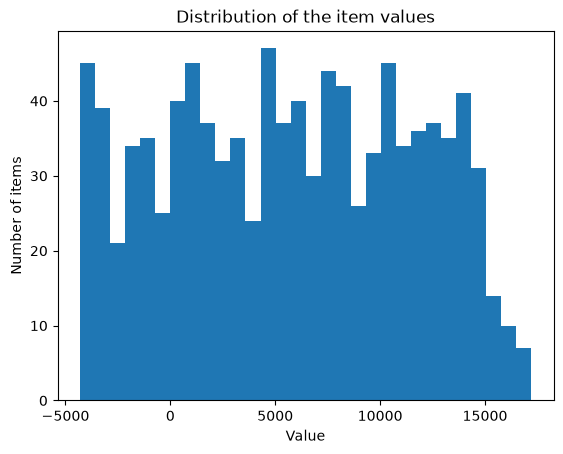

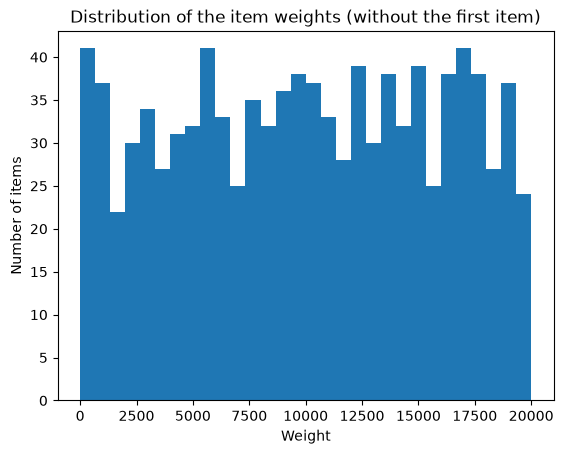

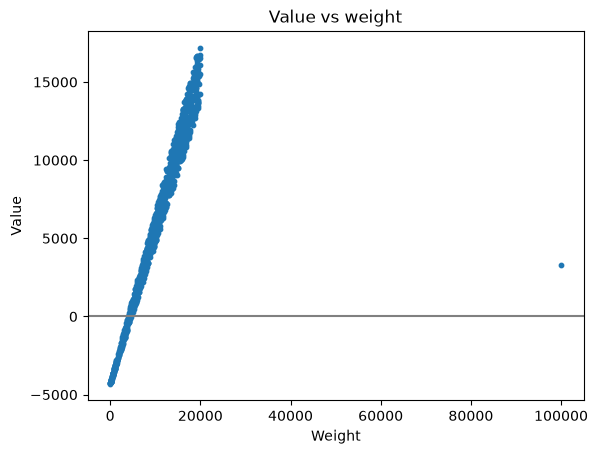

In [27]:
# Plots
plt.hist(item_values, bins=30)
plt.xlabel("Value")
plt.ylabel("Number of items")
plt.title("Distribution of the item values")
plt.show()

plt.hist(item_weights[1:], bins=30)
plt.xlabel("Weight")
plt.ylabel("Number of items")
plt.title("Distribution of the item weights (without the first item)")
plt.show()

plt.scatter(item_weights, item_values, s=10)
plt.axhline(0, color="grey")
plt.xlabel("Weight")
plt.ylabel("Value")
plt.title("Value vs weight")
plt.show()

### 2.2 New initialization function

In [28]:
def new_initialization_population(pop_size):
    
    population = []
    for i in range(pop_size):
        
        individual = []
        for j in range(len(item_values)):
            individual.append(random.randint(0, 1))
        population.append(individual)
        
    return population

**Check new initialization function**

In [29]:
# 4 individuals
test_population = new_initialization_population(4)
for individual in test_population:
    print("Length:", len(individual), "| items selected:", sum(individual), "| first 10 genes:", individual[:10])

Length: 1001 | items selected: 524 | first 10 genes: [1, 1, 1, 1, 1, 0, 0, 1, 1, 0]
Length: 1001 | items selected: 510 | first 10 genes: [1, 1, 0, 0, 1, 1, 1, 0, 1, 0]
Length: 1001 | items selected: 486 | first 10 genes: [1, 0, 0, 1, 0, 0, 1, 0, 1, 1]
Length: 1001 | items selected: 495 | first 10 genes: [0, 0, 0, 0, 0, 1, 1, 0, 0, 0]


### 2.3 New fitness function

In [30]:
def new_fitness(individuals):

    results = []
    for individual in individuals:

        score = 0
        for i in range(len(individual)):
            if individual[i] == 1:
                score += item_values[i]
        results.append(score)
        
    return results

**Check for new fitness function**

In [31]:
# Checks with answers we know from 2.1
n_items = len(item_values)
nothing = [0] * n_items
everything = [1] * n_items
only_first = [1] + [0] * (n_items - 1)

only_positive = []
for v in item_values:
    if v > 0:
        only_positive.append(1)
    else:
        only_positive.append(0)

print("Nothing selected: ", new_fitness([nothing])[0], "(expected 0)")
print("Everything selected: ", new_fitness([everything])[0], "(expected", sum(item_values), ")")
print("Only the first item: ", new_fitness([only_first])[0], "(expected", item_values[0], ")")
print("Only the positive items: ", new_fitness([only_positive])[0], "(expected 6231819, the best possible)")
print("Several at once: ", new_fitness([nothing, everything, only_first]))

Nothing selected:  0 (expected 0)
Everything selected:  5767936 (expected 5767936 )
Only the first item:  3300 (expected 3300 )
Only the positive items:  6231819 (expected 6231819, the best possible)
Several at once:  [0, 5767936, 3300]


### 2.4 Run SGA with new functions

In [32]:
population, population_fitness, best_history, average_history = sga(
    pop_size=30,
    n_iterations=1000,
    crossover_prob=0.9,
    mutation_prob=0.1,
    init_function=new_initialization_population,
    fitness_function=new_fitness,
    print_every=100
)

best_possible = sum(v for v in item_values if v > 0)   # all positive items, from 2.1 (for report)

print("------------------------")
print("Final average fitness:", round(average_history[-1], 2))
print("Final best fitness:", best_history[-1])
print("Best possible fitness:", best_possible, "-> the SGA reached", round(100 * best_history[-1] / best_possible, 1), "% of it")

Iteration 0: average fitness = 2901584.63, best fitness = 3212016
Iteration 100: average fitness = 3809975.63, best fitness = 3862534
Iteration 200: average fitness = 3910463.97, best fitness = 3973884
Iteration 300: average fitness = 3982486.37, best fitness = 4035310
Iteration 400: average fitness = 4007828.87, best fitness = 4074153
Iteration 500: average fitness = 4035709.43, best fitness = 4090199
Iteration 600: average fitness = 4066537.9, best fitness = 4169569
Iteration 700: average fitness = 4086705.9, best fitness = 4169569
Iteration 800: average fitness = 4105335.3, best fitness = 4179318
Iteration 900: average fitness = 4123956.03, best fitness = 4184038
Iteration 1000: average fitness = 4138048.17, best fitness = 4217202
------------------------
Final average fitness: 4138048.17
Final best fitness: 4217202
Best possible fitness: 6231819 -> the SGA reached 67.7 % of it


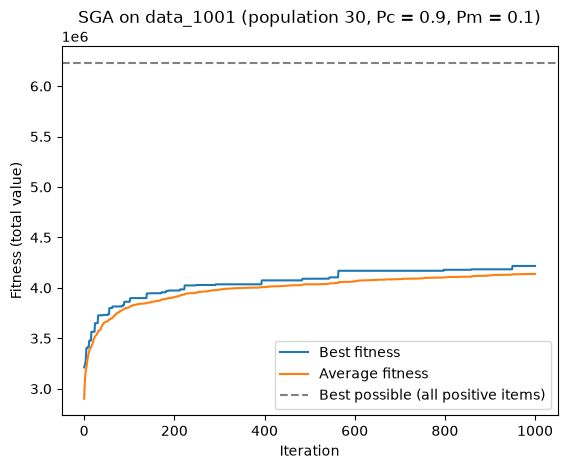

In [33]:
# Plot
plt.plot(best_history, label="Best fitness")
plt.plot(average_history, label="Average fitness")
plt.axhline(best_possible, color="grey", linestyle="--", label="Best possible (all positive items)")
plt.xlabel("Iteration")
plt.ylabel("Fitness (total value)")
plt.title("SGA on data_1001 (population 30, Pc = 0.9, Pm = 0.1)")
plt.legend()
plt.show()

### 2.5 Solution description

In [34]:
# best individual of the final population
best_individual = population[population_fitness.index(max(population_fitness))]

data["Ratio"] = data["Value"] / data["Weight"]
selected = data[[gene == 1 for gene in best_individual]]
not_selected = data[[gene == 0 for gene in best_individual]]

print("Fitness of the best solution:", max(population_fitness))
print("Items selected:", len(selected), "| not selected:", len(not_selected))
print("Negative-value items selected:", (selected["Value"] < 0).sum(), "of", (data["Value"] < 0).sum())
print("Positive-value items not selected:", (not_selected["Value"] > 0).sum(), "of", (data["Value"] > 0).sum())
print()
print("Selected items:")
print(selected[["Value", "Weight", "Ratio"]].agg(["min", "mean", "max"]).round(3))
print()
print("Not selected items:")
print(not_selected[["Value", "Weight", "Ratio"]].agg(["min", "mean", "max"]).round(3))

Fitness of the best solution: 4217202
Items selected: 621 | not selected: 380
Negative-value items selected: 93 of 199
Positive-value items not selected: 274 of 802

Selected items:
          Value     Weight     Ratio
min   -4299.000      1.000 -4299.000
mean   6790.986  11034.754    -7.247
max   16716.000  19978.000     0.868

Not selected items:
          Value      Weight    Ratio
min   -4262.000      38.000 -112.158
mean   4080.879    8662.016   -1.064
max   17195.000  100000.000    0.869


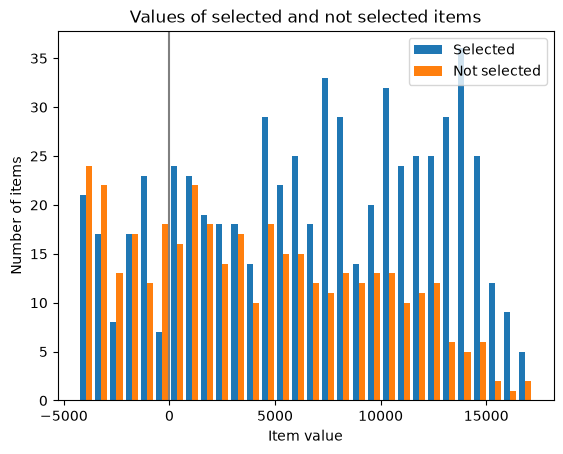

In [35]:
# Plot
plt.hist([selected["Value"], not_selected["Value"]], bins=30, label=["Selected", "Not selected"])
plt.axvline(0, color="grey")
plt.xlabel("Item value")
plt.ylabel("Number of items")
plt.title("Values of selected and not selected items")
plt.legend()
plt.show()

**check for selection pressure**

In [36]:
# How strong is parent selection at the end
probabilities = [f / sum(population_fitness) for f in population_fitness]
print("Highest selection probability:", round(max(probabilities), 4))
print("Lowest selection probability: ", round(min(probabilities), 4))
print("If every individual had the same chance:", round(1 / len(population), 4))

Highest selection probability: 0.034
Lowest selection probability:  0.0331
If every individual had the same chance: 0.0333


**check mutation rate**

Pm = 1/1001: best fitness = 6215759 -> 99.7 % of the best possible
Pm = 0.1:    best fitness = 4217202 -> 67.7 % of the best possible


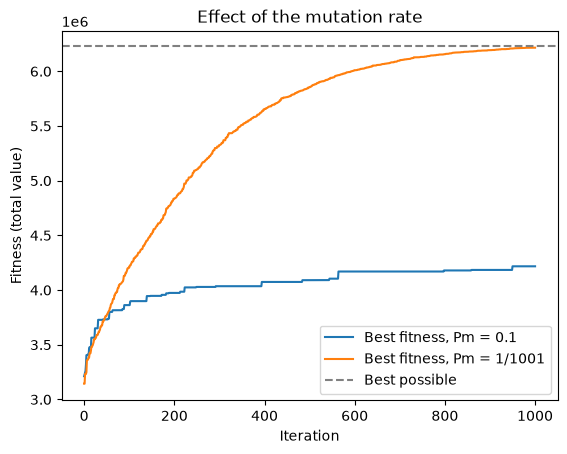

In [37]:
# The same run with a much lower mutation rate, Pm = 1/1001
population_low, fitness_low, best_low, average_low = sga(30, 1000, 0.9, 1 / len(item_values),
                                                         init_function=new_initialization_population,
                                                         fitness_function=new_fitness, print_every=0)

print("Pm = 1/1001: best fitness =", best_low[-1], "->", round(100 * best_low[-1] / best_possible, 1), "% of the best possible")
print("Pm = 0.1:    best fitness =", best_history[-1], "->", round(100 * best_history[-1] / best_possible, 1), "% of the best possible")

plt.plot(best_history, label="Best fitness, Pm = 0.1")
plt.plot(best_low, label="Best fitness, Pm = 1/1001")
plt.axhline(best_possible, color="grey", linestyle="--", label="Best possible")
plt.xlabel("Iteration")
plt.ylabel("Fitness (total value)")
plt.title("Effect of the mutation rate")
plt.legend()
plt.show()

---
## Task 3: Knapsack ”data 1001” with Constraint

### 3.1 SGA Functions

**Discussion**

So first of all, the initialization function needs to be updated. That is because currently we are looping through the population size and randomly choosing 0 or 1 for each item. This can lead to individual having more than 10 items, hence needs to be changed. To change, we can simply run the random function 10 times to select ten indexes for each 1. We would start of by having everything set to zero, and then change the random indexes to 1, resulting in always 10 picked items. 

So next, we need to change the crossover function. Currently what we are doing is that we find a crossover index for two parents and swap before that index, creating new offspring. However, this can lead to offspring having more than 10 items. Because we don't take into account how many items are already selected up until that index, nor after. 

Lastly, we have to modify mutation function. Because current method loops through the items and uses probability to determine if to flip the individual. Which can result, in more than 10 items because aren't fixing anything after the flip. 

### 3.2

In [40]:
def new_initialization_population(pop_size, k):
    
    population = []
    for i in range(pop_size):
        
        individual = []

        for _ in range(1001):
            individual.append(0)

        selected_indexes = random.sample(range(1001), k)

        for i in selected_indexes:
            individual[i] = 1
            
        population.append(individual)
        
    return population



def new_one_point_crossover(parents, crossover_prob, k):
     
    off_spring = []

    for i in range(0, len(parents), 2):

        if i == len(parents) - 1:
            off_spring.append(parents[i].copy())
            break

        number = random.random()   
        if number > crossover_prob:
            off_spring.append(parents[i].copy())
            off_spring.append(parents[i+1].copy())
            continue

        crossover_point = random.randint(1, len(parents[i]) - 1)

        offspring1 = parents[i]
        offspring2 = parents[i+1]

        prefix1 = offspring1[:crossover_point]
        prefix2 = offspring2[:crossover_point]

        pool = []

        for j in range(crossover_point, len(offspring1)):
            if offspring1[j] == 1 or offspring2[j] == 1:
                pool.append(j)
        
        selected1 = set(random.sample(pool, k - sum(prefix1)))
        selected2 = set(random.sample(pool, k - sum(prefix2)))
        
        suffix1 = []
        suffix2 = []
        
        for j in range(crossover_point, len(offspring1)):
            if j in selected1:
                suffix1.append(1)
            else:
                suffix1.append(0)
        
        for j in range(crossover_point, len(offspring2)):
            if j in selected2:
                suffix2.append(1)
            else:
                suffix2.append(0)
        
        new_offspring1 = prefix1 + suffix1
        new_offspring2 = prefix2 + suffix2

        off_spring.append(new_offspring1)
        off_spring.append(new_offspring2)

    return off_spring


def new_mutation(individuals, pm):

    mutated_population = []

    for individual in individuals:
        new_individual = individual.copy()

        random_number = random.random()

        if random_number <= pm:
            
            ones_index = []
            zeros_index = []

            for position in range(len(new_individual)):
                if new_individual[position] == 1:
                    ones_index.append(position)
                else:
                    zeros_index.append(position)

            if len(ones_index) > 0 and len(zeros_index) > 0:
                selected_position = random.choice(ones_index)
                unselected_position = random.choice(zeros_index)

                new_individual[selected_position] = 0
                new_individual[unselected_position] = 1

        mutated_population.append(new_individual)

    return mutated_population


In [39]:

for k in [1001, 900, 802, 600, 400, 200, 100, 10]:

    population, population_fitness, best_history, average_history = sga(
        pop_size=30,
        n_iterations=1000,
        crossover_prob=0.9,
        mutation_prob=0.1,
        init_function=new_initialization_population,
        fitness_function=new_fitness,
        crossover_function=new_one_point_crossover,
        mutation_function=new_mutation,
        print_every=0, 
        k = k
    )

    best_fitness = max(population_fitness)
    best_index = population_fitness.index(best_fitness)
    best_individual = population[best_index]
    number_of_items = sum(best_individual)

    print()
    print("For k:", k)
    print("Highest fitness:", best_fitness)
    print("Number of items:", number_of_items)
    print("Average value per selected item:", best_fitness / number_of_items)



For k: 1001
Highest fitness: 5767936
Number of items: 1001
Average value per selected item: 5762.1738261738265

For k: 900
Highest fitness: 6057571
Number of items: 900
Average value per selected item: 6730.634444444445

For k: 802
Highest fitness: 6020738
Number of items: 802
Average value per selected item: 7507.154613466334

For k: 600
Highest fitness: 5371226
Number of items: 600
Average value per selected item: 8952.043333333333

For k: 400
Highest fitness: 4304637
Number of items: 400
Average value per selected item: 10761.5925

For k: 200
Highest fitness: 2598543
Number of items: 200
Average value per selected item: 12992.715

For k: 100
Highest fitness: 1445114
Number of items: 100
Average value per selected item: 14451.14

For k: 10
Highest fitness: 165903
Number of items: 10
Average value per selected item: 16590.3


**Comments**

So as we can see the number of items influences the fitness a lot. We can see clearly then when k decreases, avg value increases. The overall best fitness decreases (except with first value), but that makes sense because we have fewer items.

However, the avg value increases which is good. However, we are always trying to maximize the total fitness, so having higher avg value doesn't always mean that we are picking the best solution (the highest fitness), but is a good indicator of it. This indicates that the model picks fewer but better choices. 

Starting with 1001, we can see that it doesn't get the highest overall fitness. This makes sense because the data set also contains negatives, and if we summon everything up we won't get the best fitness possible. To get the best fitness possible, we would need to exclude some of the items.

We can see that with k = 900, the overall fitness is higher. That is because we aren't picking some of the negatives. This number decreases as k decreases. That is because we have fewer items which we can summon up. 

However, The highest total fitness is when k = 802, because that's number of all positive values. But at this value we aren't reaching the highest total fitness. But that is normal, because this algorythm is trying to find the best solution, but doesn't always find it. But a sign that its behaving right, is that we are very close to the best total fitness. 

Everything behaves as expected, if we have fewer k's we won't be able to get the best possible fitness (When going k< 802). 

### 3.3

**Upper bound:**

So for the upper bound we would need to change the initilazation, crossover and mutation function. 

Now if we have a upper bound we would need to change initilazation, because now we can also have number of items which is lower than then k. So we don't simply choose k indexes (randomly), but also have to decide on what value k takes. Which can just be done randomly. So now we would start with randomly choosing a k which is equal or lower then the upper bound. Next,we continue like before but with the new k. So we choose k random indexes for 1's. 

Crossover needs to change because with our currect function we are assuming that the number of items has to stay the same. Now if we can also have number of items which is lower, we for example don't have to change the suffix after crossover if number of 1's is lower then k (Which we didn't allow before). So in our new function we could have a probability or randomnes decide if we continue adding 1's to the suffix after the crossover. Before we pooled everything together and choose randomly up until we reached the desired number of items. Now we can just continue picking 1's in a range, and using probability to decide to keep the 1 or not. 

Then mutation has to change, because before when choosing 1 to swap, we also had to find corresponding 0 to swap with. To keep the same number of items. But now, for example we won't need to do that. So this is why we need to update the function. So now we would just simply choose an random index and flip the bit. The only thing we would check is if the number of items isn't equal to the bound. However, changing 1 to 0 will always be allowed because that won't change the bound. 


**Upper bound of the summed weights.**

So like before we need to change initilazation, crossover and mutation function. So we need to change initlazation function because we can't just randomly choose k number of items, because we aren't considering the weights. What we can do, is to randomly choose a item and add its weight to a sum. Now if the item doesn't go above our upper bound we can add it. 

We also need to change crossover, because we aren't considering the weights at all and need to calculate new weights after the crossover has been done and when calculating the suffix. We can safely copy the elements from the prefix, because if they were there before then they must be lower then the bound, but we need to think about the suffix. So for the suffix we can simply pool again the available items from both parents and randomly choose. When choosen, check if the sum of weights won't exced the upper bound. 

Lastly we need to change the mutation function because swapping indexes can change the weight sum. Now we update the func so that flipping 1 to 0, is always allowed. Because it can't increase the weight. But now when changing 0 to 1, we check if it satisfies our constraint. If it does we add it, if not, we don't add it. 
